# 1 Setup
Imports the required libraries, sets the default plot style and defines the input/output paths used throughout the EDA notebook. Figures are saved to `results/figures/eda/`.

In [22]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

data_path = Path("../data/creditcard.csv")
output_dir = Path("../results/figures/eda")
output_dir.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(data_path)

print("Dataset loaded successfully.")
print(f"Shape: {df.shape}")

Dataset loaded successfully.
Shape: (284807, 31)


# 2. Dataset Overview

Initial inspection of structure, data types, missing values and summary statistics. Confirms the dataset is complete and fully numerical with no missing-value handling or categorical encoding required before modelling.

In [23]:
print(f"Dataset shape: {df.shape}")

dataset_summary = pd.DataFrame({
    "Dataset property": [
        "Rows",
        "Columns",
        "Feature columns",
        "Target column",
        "Feature data types",
        "Target data type",
        "Target labels"
    ],
    "Value": [
        f"{df.shape[0]:,}",
        f"{df.shape[1]}",
        "Time, V1-V28, Amount",
        "Class",
        "Numeric floating-point values",
        str(df["Class"].dtype),
        "0 = legitimate, 1 = fraud"
    ]
})

display(dataset_summary)

missing_summary = pd.DataFrame({
    "Check": [
        "Missing values in Time",
        "Missing values in V1-V28",
        "Missing values in Amount",
        "Missing values in Class"
    ],
    "Result": [
        int(df["Time"].isnull().sum()),
        int(df[[f"V{i}" for i in range(1, 29)]].isnull().sum().sum()),
        int(df["Amount"].isnull().sum()),
        int(df["Class"].isnull().sum())
    ]
})

display(missing_summary)

display(df.head())

Dataset shape: (284807, 31)


,Dataset property,Value
0,Rows,"284,807"
1,Columns,31
2,Feature columns,"Time, V1-V28, Amount"
3,Target column,Class
4,Feature data types,Numeric floating-point values
5,Target data type,int64
6,Target labels,"0 = legitimate, 1 = fraud"


,Check,Result
0,Missing values in Time,0
1,Missing values in V1-V28,0
2,Missing values in Amount,0
3,Missing values in Class,0


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


# 3. Class Distribution

Fraud accounts for approximately 0.17% of all transactions. This severe imbalance motivates the use of imbalance-aware evaluation metrics, with PR-AUC used as the primary metric and F1-score used as a supporting metric. It also supports the use of resampling strategies in the modelling pipeline.

Class counts:
Class
0    284315
1       492
Name: count, dtype: int64

Class percentages:
Class
0    99.8273
1     0.1727
Name: proportion, dtype: float64


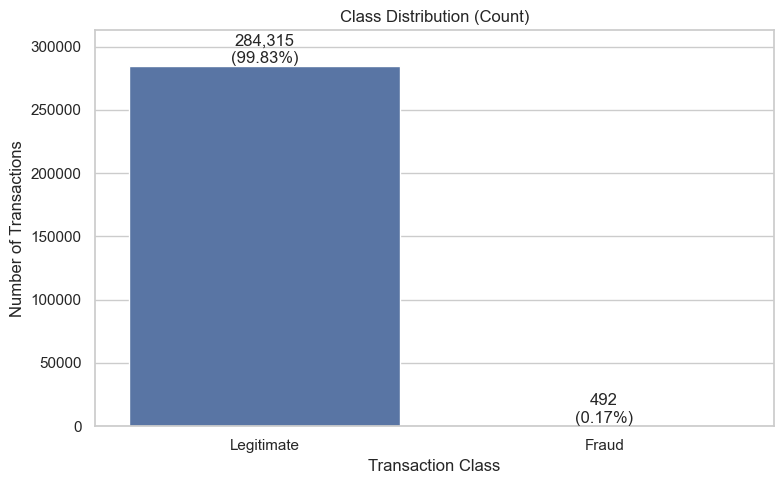

In [24]:
# sort_index() ensures 0 = Legitimate, 1 = Fraud throughout
class_counts = df["Class"].value_counts().sort_index()
class_percent = df["Class"].value_counts(normalize=True).sort_index() * 100

print("Class counts:")
print(class_counts)

print("\nClass percentages:")
print(class_percent.round(4))


plt.figure()

sns.barplot(
    x=["Legitimate", "Fraud"],
    y=class_counts.values,
)

plt.title("Class Distribution (Count)")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")

for i, value in enumerate(class_counts.values):
    percent = class_percent.iloc[i]
    plt.text(
        i,
        value,
        f"{value:,}\n({percent:.2f}%)",
        ha="center",
        va="bottom",
    )

plt.ylim(0, class_counts.max() * 1.1)  # headroom for bar annotations

plt.tight_layout()
plt.savefig(output_dir / "eda_class_distribution.png", dpi=300)
plt.show()

# 4. Amount Distribution

Transaction amounts are heavily right-skewed, with considerable overlap between classes. A log scale is applied to the frequency axis to make the distribution readable. The wide range of `Amount` supports scaling before applying distance-based resampling methods in the modelling pipeline.

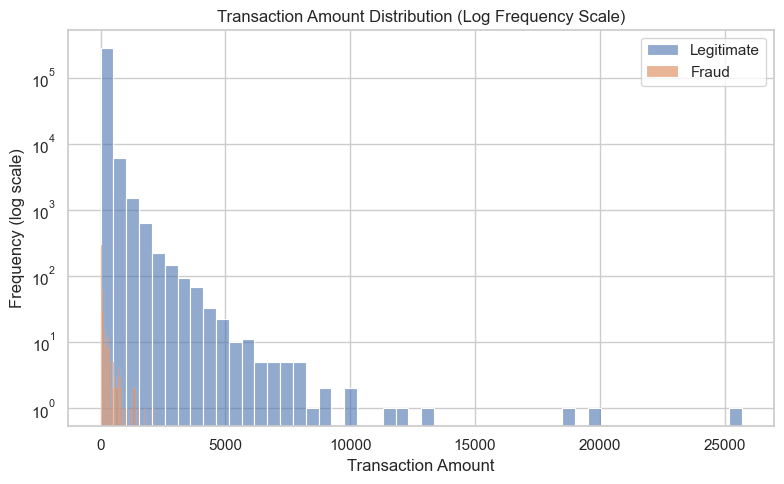

In [25]:
legit_amount = df[df["Class"] == 0]["Amount"]
fraud_amount = df[df["Class"] == 1]["Amount"]

plt.figure()

sns.histplot(legit_amount, bins=50, label="Legitimate", alpha=0.6, stat="count")
sns.histplot(fraud_amount, bins=50, label="Fraud", alpha=0.6, stat="count")

plt.yscale("log")  # extreme count skew makes linear scale unreadable

plt.title("Transaction Amount Distribution (Log Frequency Scale)")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency (log scale)")
plt.legend()

plt.tight_layout()
plt.savefig(output_dir / "eda_amount_distribution.png", dpi=300)
plt.show()

# 5. Time Distribution

Transactions are examined across the full 48-hour window. The second plot uses proportional frequencies to allow fair comparison despite the class imbalance.

Both classes show overlapping temporal patterns, with no clear separation based on `Time` alone. `Time` is therefore retained as a feature but scaled before distance-based resampling is applied in the modelling pipeline.

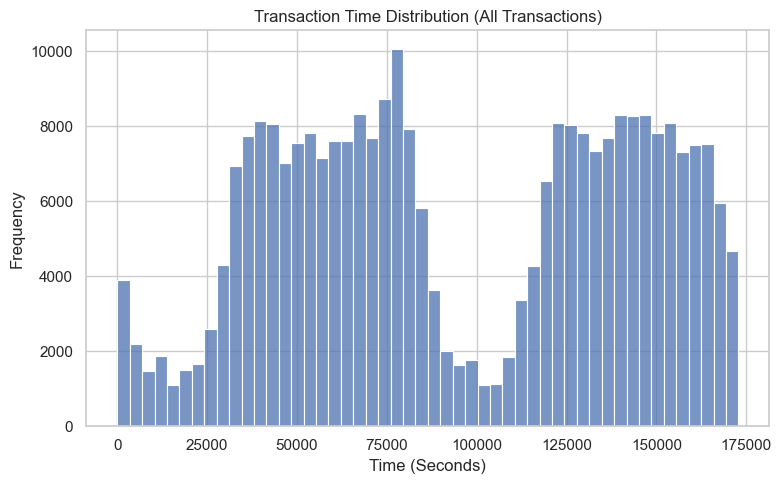

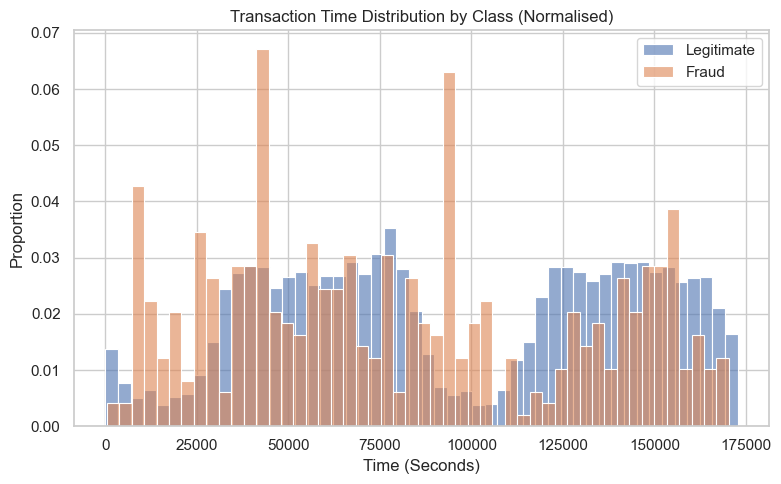

In [26]:
legit_time = df[df["Class"] == 0]["Time"]
fraud_time = df[df["Class"] == 1]["Time"]

plt.figure()
sns.histplot(df["Time"], bins=50, stat="count")
plt.title("Transaction Time Distribution (All Transactions)")
plt.xlabel("Time (Seconds)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig(output_dir / "eda_time_distribution.png", dpi=300)
plt.show()


plt.figure()
sns.histplot(legit_time, bins=50, label="Legitimate", alpha=0.6, stat="probability")
sns.histplot(fraud_time, bins=50, label="Fraud", alpha=0.6, stat="probability")
# stat="probability" normalises by class size so the shapes are comparable
# despite the large difference in sample counts between classes
plt.title("Transaction Time Distribution by Class (Normalised)")
plt.xlabel("Time (Seconds)")
plt.ylabel("Proportion")
plt.legend()
plt.tight_layout()
plt.savefig(output_dir / "eda_time_distribution_by_class.png", dpi=300)
plt.show()

# 6. Correlation Heatmap

Correlations between PCA-transformed features V1-V28 are examined to understand the structure of the anonymised feature set. As expected from PCA-transformed variables, the features show little visible linear correlation, so V1-V28 are retained without further transformation in the modelling pipeline.

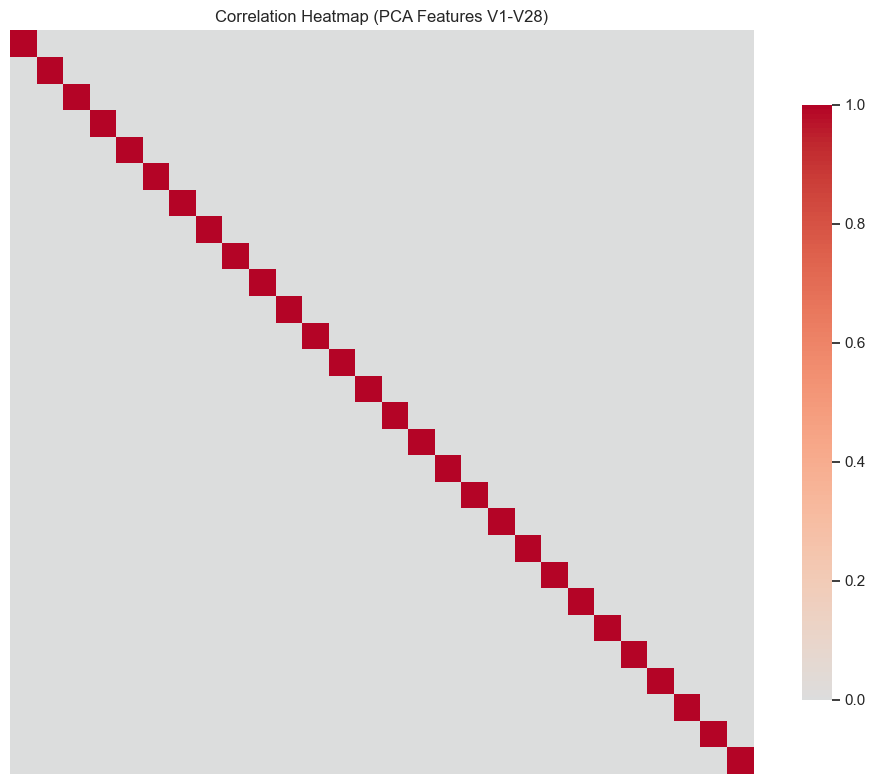

In [27]:
v_features = [col for col in df.columns if col.startswith("V")]
corr = df[v_features].corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    square=True,
    cbar=True,
    cbar_kws={"shrink": 0.8},
    xticklabels=False,
    yticklabels=False,
)

plt.title("Correlation Heatmap (PCA Features V1-V28)")
plt.tight_layout()
plt.savefig(output_dir / "eda_correlation_heatmap.png", dpi=300)
plt.show()

# 7. Distribution Comparison (Violin Plots)

Violin plots compare the distribution shape of `Amount` and `Time` across both classes. A log scale is applied to `Amount` due to its strong right skew. The `Time` distributions overlap substantially, supporting the earlier observation that `Time` alone does not clearly separate legitimate and fraudulent transactions.

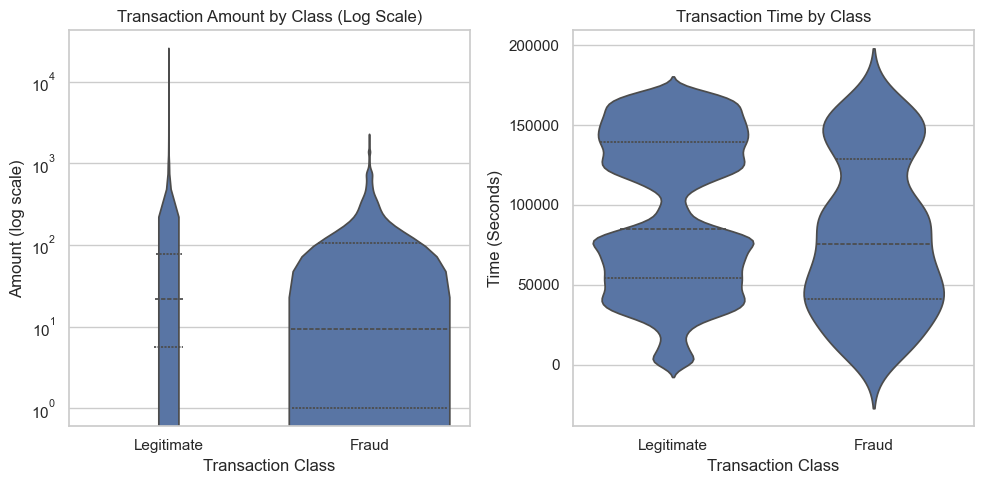

In [28]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
sns.violinplot(
    x="Class",
    y="Amount",
    data=df,
    inner="quartile",  # shows median and IQR inside the violin
)
plt.yscale("log")  # extreme skew in Amount makes linear scale unreadable
plt.xticks([0, 1], ["Legitimate", "Fraud"])
plt.title("Transaction Amount by Class (Log Scale)")
plt.xlabel("Transaction Class")
plt.ylabel("Amount (log scale)")

plt.subplot(1, 2, 2)
sns.violinplot(
    x="Class",
    y="Time",
    data=df,
    inner="quartile",
)
plt.xticks([0, 1], ["Legitimate", "Fraud"])
plt.title("Transaction Time by Class")
plt.xlabel("Transaction Class")
plt.ylabel("Time (Seconds)")

plt.tight_layout()
plt.savefig(output_dir / "eda_amount_time_violin.png", dpi=300)
plt.show()

## 8. Summary and Pipeline Implications

At approximately 0.17% of all transactions, the fraud class is extremely rare. This confirms that the dataset is severely imbalanced and that accuracy would not give a meaningful view of fraud detection performance.

The Amount feature is heavily right-skewed and shows substantial overlap between legitimate and fraudulent transactions. This suggests that Amount may still be useful but it should be scaled before modelling and before distance-based resampling methods are applied.

The Time feature covers a continuous 48-hour period. The class-based time plots show overlap between legitimate and fraudulent transactions, so Time alone does not clearly separate the two classes. However, it is still retained because it may contribute when combined with the other features.

The PCA-transformed features V1 to V28 show little visible linear correlation. This supports retaining them as provided, without applying additional feature engineering in the EDA stage.

Overall, the EDA confirms three important points for the modelling pipeline: the dataset is complete and numerical, the target class is severely imbalanced and Amount and Time should be scaled before training and resampling.